In [2]:
from pathlib import Path

In [3]:
DATA = Path("../data")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

In [4]:
import rasterio, numpy as np, matplotlib.pyplot as plt

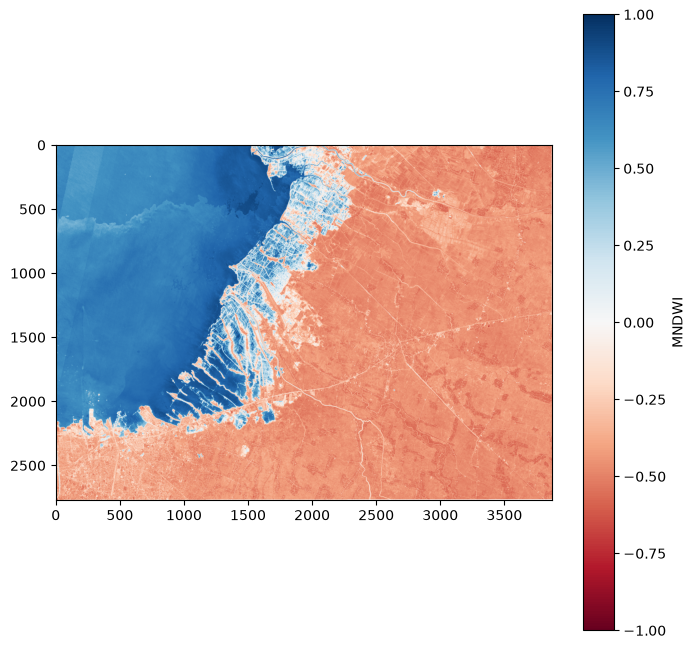

In [5]:
path = DATA / "demak_2018.tif"
with rasterio.open(path) as src:
    mndwi = src.read(1).astype("float32")   # band 1 = water index
    ndvi = src.read(2).astype("float32")    # band 2 = vegetation index

# pixels with no data (clouds) are NaN or 0 in both bands
valid = np.isfinite(mndwi) & ~((mndwi == 0) & (ndvi == 0))

plt.figure(figsize=(8,8))
plt.imshow(np.where(valid, mndwi, np.nan), cmap = "RdBu", vmin = -1, vmax = 1)
plt.colorbar(label="MNDWI")
plt.show()

Otsu threshold: 0.11744964


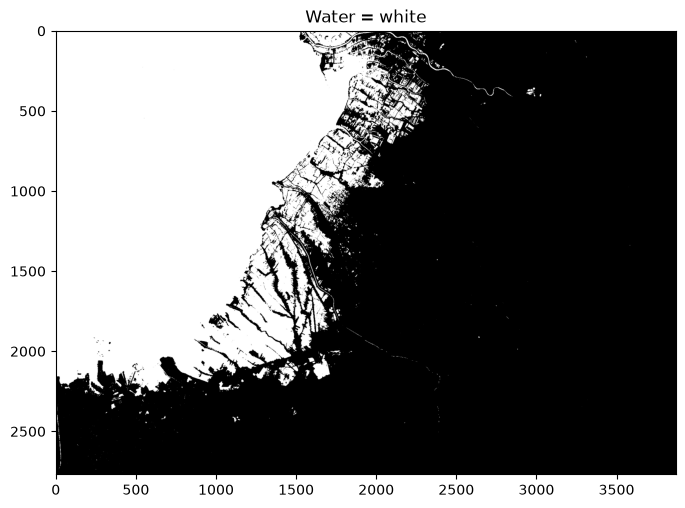

In [6]:
from skimage.filters import threshold_otsu

t = threshold_otsu(mndwi[valid])
print("Otsu threshold:", t)

water = (mndwi > t) & valid
plt.figure(figsize=(8, 8))
plt.imshow(water, cmap="gray")
plt.title("Water = white")
plt.show()

2018 threshold: 0.117 lines: 321
2019 threshold: 0.157 lines: 205
2020 threshold: 0.145 lines: 310
2021 threshold: 0.148 lines: 274
2022 threshold: 0.159 lines: 304
2023 threshold: 0.155 lines: 295
2024 threshold: 0.149 lines: 341


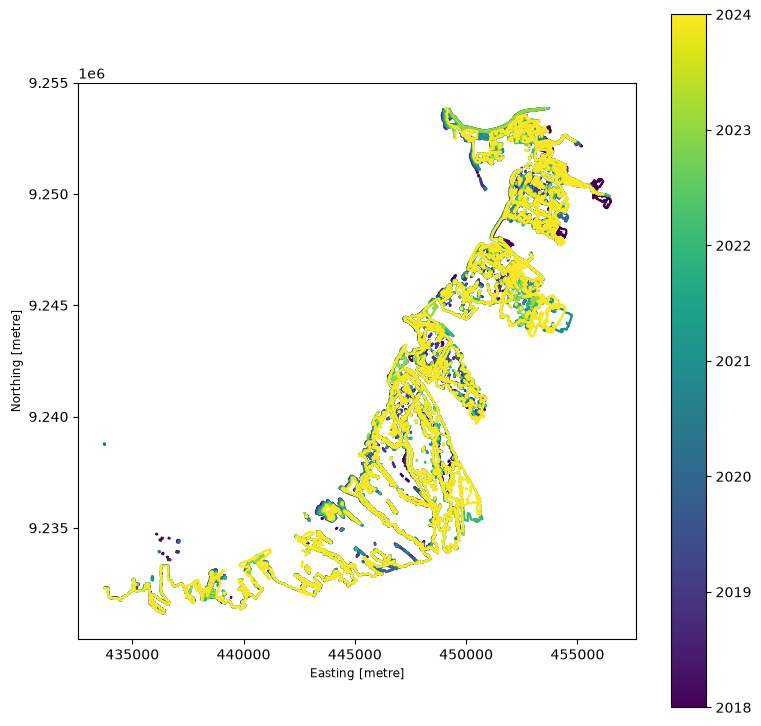

In [ ]:
import glob, geopandas as gpd
from scipy import ndimage
from skimage import measure
from shapely.geometry import LineString

def extract_shoreline(path):
    with rasterio.open(path) as src:
        m = src.read(1).astype("float32") # band 1 = water index
        n = src.read(2).astype("float32") # band 2 = vegetaioin index (land)
        transform = src.transform
    valid = np.isfinite(m) & ~((m == 0) & (n == 0))
    t = threshold_otsu(m[valid])
    water = (m > t) & valid

    # keep only the biggest connected water body (the sea)
    labels, k = ndimage.label(water)
    sizes = ndimage.sum(water, labels, range(1, k + 1))
    sea = labels == (np.argmax(sizes) + 1)

    m2 = m.copy()
    m2[water & ~sea] = -1.0          # ponds and rivers count as land

    lines = []
    for c in measure.find_contours(m2, t, mask=valid):
        if len(c) < 20:               # drop tiny fragments
            continue
        xy = [transform * (col + 0.5, row + 0.5) for row, col in c]
        lines.append(LineString(xy))
    return lines, t, src.crs

rows, crs = [], None
for p in sorted(DATA.glob("demak_*.tif")):
    year = int(p.stem.split("_")[1])
    lines, t, crs = extract_shoreline(p)
    print(year, "threshold:", round(float(t), 3), "lines:", len(lines))
    for ln in lines:
        rows.append({"year": year, "geometry": ln})

shore = gpd.GeoDataFrame(rows, crs=crs)
shore.to_file(RESULTS / "shorelines.GeoJSON", driver="GeoJSON")

shore.plot(column="year", cmap="viridis", legend=True, figsize=(9, 9))
plt.savefig(RESULTS / "shoreline.png")
plt.show()
